In [1]:
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, UnidentifiedImageError

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Original BRISC2025 dataset location
DATASET_ROOT = Path(r"D:\brain tumour\brisc2025")

CLASSIFICATION_ROOT = DATASET_ROOT / "classification_task"

TRAIN_DIR = CLASSIFICATION_ROOT / "train"
TEST_DIR = CLASSIFICATION_ROOT / "test"

# Four classification categories
CLASSES = [
    "glioma",
    "meningioma",
    "no_tumor",
    "pituitary"
]

# Verify paths
print("Dataset exists:", DATASET_ROOT.exists())
print("Classification directory exists:", CLASSIFICATION_ROOT.exists())
print("Training directory exists:", TRAIN_DIR.exists())
print("Testing directory exists:", TEST_DIR.exists())

Dataset exists: True
Classification directory exists: True
Training directory exists: True
Testing directory exists: True


In [3]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def get_image_files(directory):
    return [
        path for path in directory.rglob("*")
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    ]


dataset_summary = []

for split_name, split_dir in [
    ("Train", TRAIN_DIR),
    ("Test", TEST_DIR)
]:
    for class_name in CLASSES:

        class_dir = split_dir / class_name
        images = get_image_files(class_dir)

        dataset_summary.append({
            "Split": split_name,
            "Class": class_name,
            "Image_Count": len(images)
        })


summary_df = pd.DataFrame(dataset_summary)

print(summary_df.to_string(index=False))

print("\nTotal images:", summary_df["Image_Count"].sum())

Split      Class  Image_Count
Train     glioma         1147
Train meningioma         1329
Train   no_tumor         1067
Train  pituitary         1457
 Test     glioma          254
 Test meningioma          306
 Test   no_tumor          140
 Test  pituitary          300

Total images: 6000


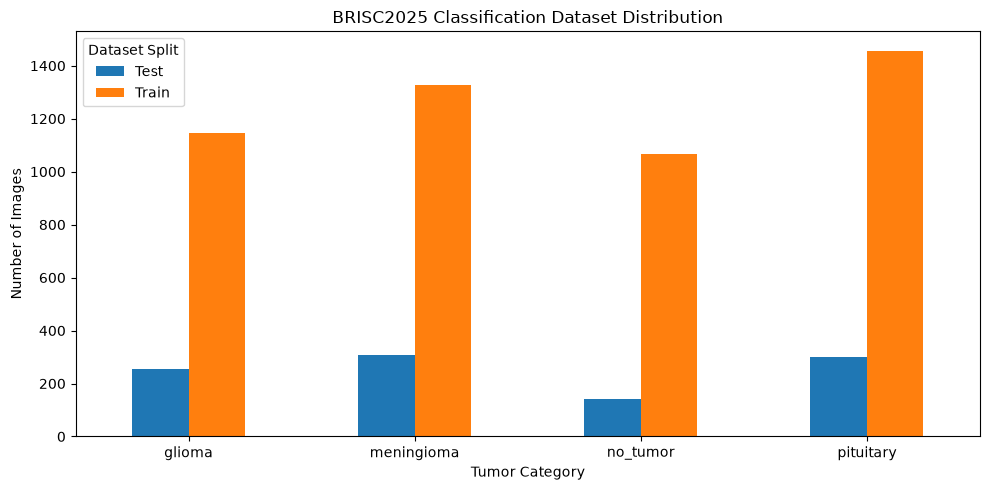

In [4]:
distribution = summary_df.pivot(
    index="Class",
    columns="Split",
    values="Image_Count"
)

distribution.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("BRISC2025 Classification Dataset Distribution")
plt.xlabel("Tumor Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.legend(title="Dataset Split")
plt.tight_layout()
plt.show()

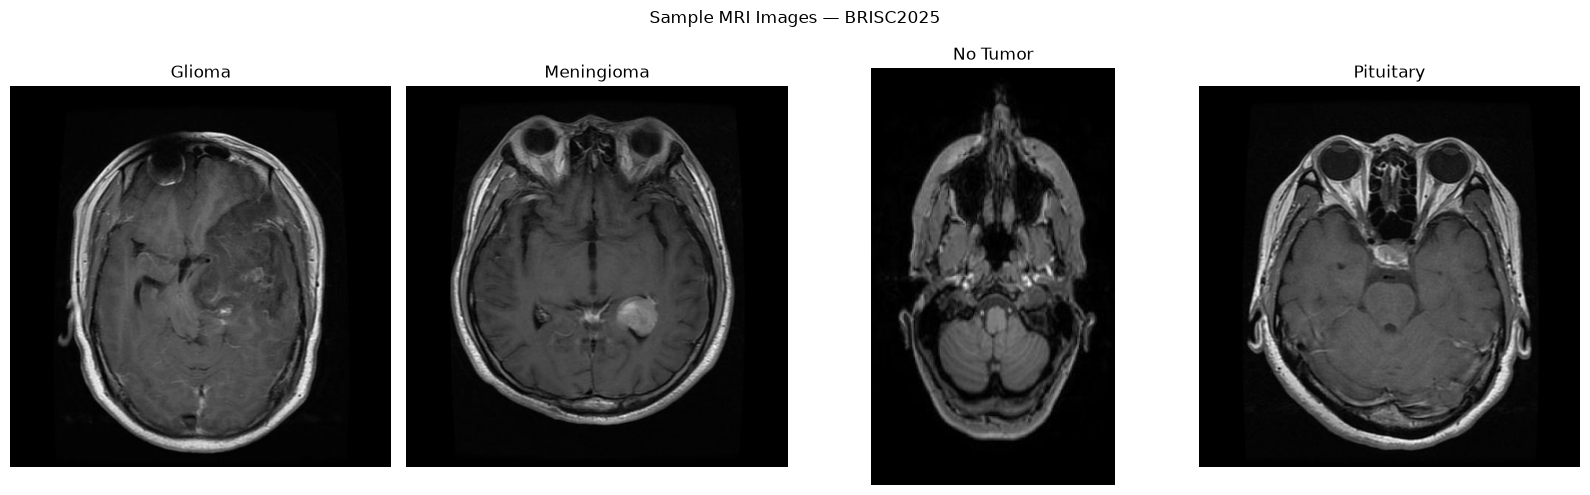

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for ax, class_name in zip(axes, CLASSES):

    class_images = get_image_files(TRAIN_DIR / class_name)

    if not class_images:
        ax.set_title(f"{class_name}\nNo images found")
        ax.axis("off")
        continue

    image_path = class_images[0]

    image = Image.open(image_path)

    ax.imshow(image, cmap="gray")
    ax.set_title(class_name.replace("_", " ").title())
    ax.axis("off")

plt.suptitle("Sample MRI Images — BRISC2025")
plt.tight_layout()
plt.show()

In [6]:
image_records = []
corrupted_images = []

for split_name, split_dir in [
    ("Train", TRAIN_DIR),
    ("Test", TEST_DIR)
]:
    for class_name in CLASSES:

        for image_path in get_image_files(split_dir / class_name):

            try:
                with Image.open(image_path) as image:
                    image_records.append({
                        "Split": split_name,
                        "Class": class_name,
                        "Filename": image_path.name,
                        "Width": image.width,
                        "Height": image.height,
                        "Mode": image.mode,
                        "Format": image.format
                    })

            except (OSError, UnidentifiedImageError):
                corrupted_images.append(str(image_path))


image_df = pd.DataFrame(image_records)

print("Successfully inspected:", len(image_df))
print("Corrupted images:", len(corrupted_images))

print("\nImage dimensions:")
print(
    image_df.groupby(["Width", "Height"])
    .size()
    .sort_values(ascending=False)
)

print("\nImage modes:")
print(image_df["Mode"].value_counts())

print("\nImage formats:")
print(image_df["Format"].value_counts())

Successfully inspected: 6000
Corrupted images: 0

Image dimensions:
Width  Height
512    512       4881
369    369        363
216    369        354
256    256         32
187    369         21
                 ... 
1024   1024         1
1149   1019         1
1275   1427         1
1280   1280         1
1365   1365         1
Length: 183, dtype: int64

Image modes:
Mode
RGB    3134
L      2866
Name: count, dtype: int64

Image formats:
Format
JPEG    6000
Name: count, dtype: int64


In [7]:
# Calculate class distribution percentages
class_distribution = (
    summary_df
    .groupby(["Split", "Class"])["Image_Count"]
    .sum()
    .reset_index()
)

class_distribution["Percentage"] = (
    class_distribution.groupby("Split")["Image_Count"]
    .transform(lambda x: x / x.sum() * 100)
)

print(class_distribution.round(2).to_string(index=False))

Split      Class  Image_Count  Percentage
 Test     glioma          254       25.40
 Test meningioma          306       30.60
 Test   no_tumor          140       14.00
 Test  pituitary          300       30.00
Train     glioma         1147       22.94
Train meningioma         1329       26.58
Train   no_tumor         1067       21.34
Train  pituitary         1457       29.14


In [8]:
# Frequency of image dimensions
dimension_summary = (
    image_df
    .groupby(["Width", "Height"])
    .size()
    .reset_index(name="Image_Count")
    .sort_values("Image_Count", ascending=False)
)

print("Total unique dimension combinations:", len(dimension_summary))

print("\nTop 15 image dimensions:")
print(dimension_summary.head(15).to_string(index=False))

Total unique dimension combinations: 183

Top 15 image dimensions:
 Width  Height  Image_Count
   512     512         4881
   369     369          363
   216     369          354
   256     256           32
   187     369           21
   225     225           20
   202     369           19
   210     369           12
   236     236           11
   442     442           10
   455     500            5
   201     251            5
   554     554            5
   212     237            4
   200     223            4


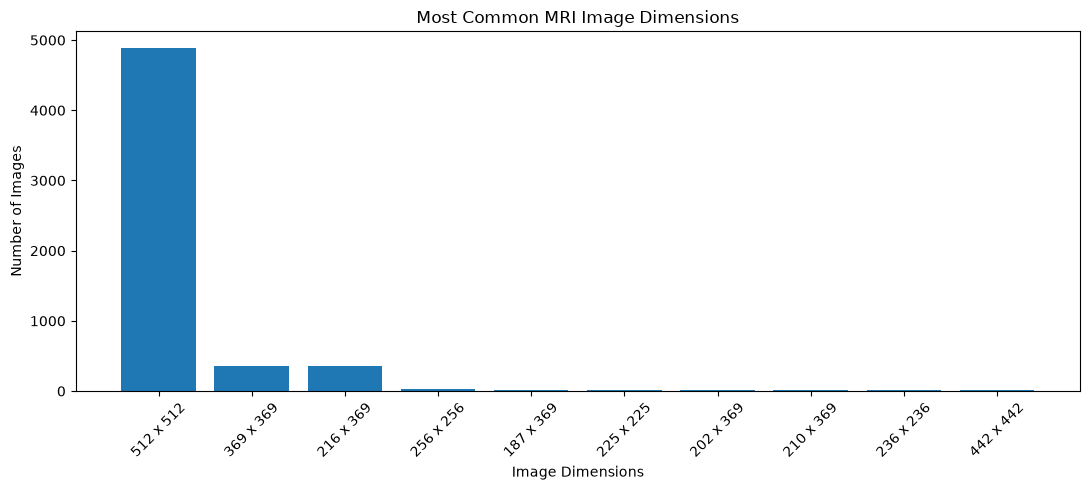

In [9]:
top_dimensions = dimension_summary.head(10).copy()

top_dimensions["Dimension"] = (
    top_dimensions["Width"].astype(str)
    + " x "
    + top_dimensions["Height"].astype(str)
)

plt.figure(figsize=(11, 5))

plt.bar(
    top_dimensions["Dimension"],
    top_dimensions["Image_Count"]
)

plt.title("Most Common MRI Image Dimensions")
plt.xlabel("Image Dimensions")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

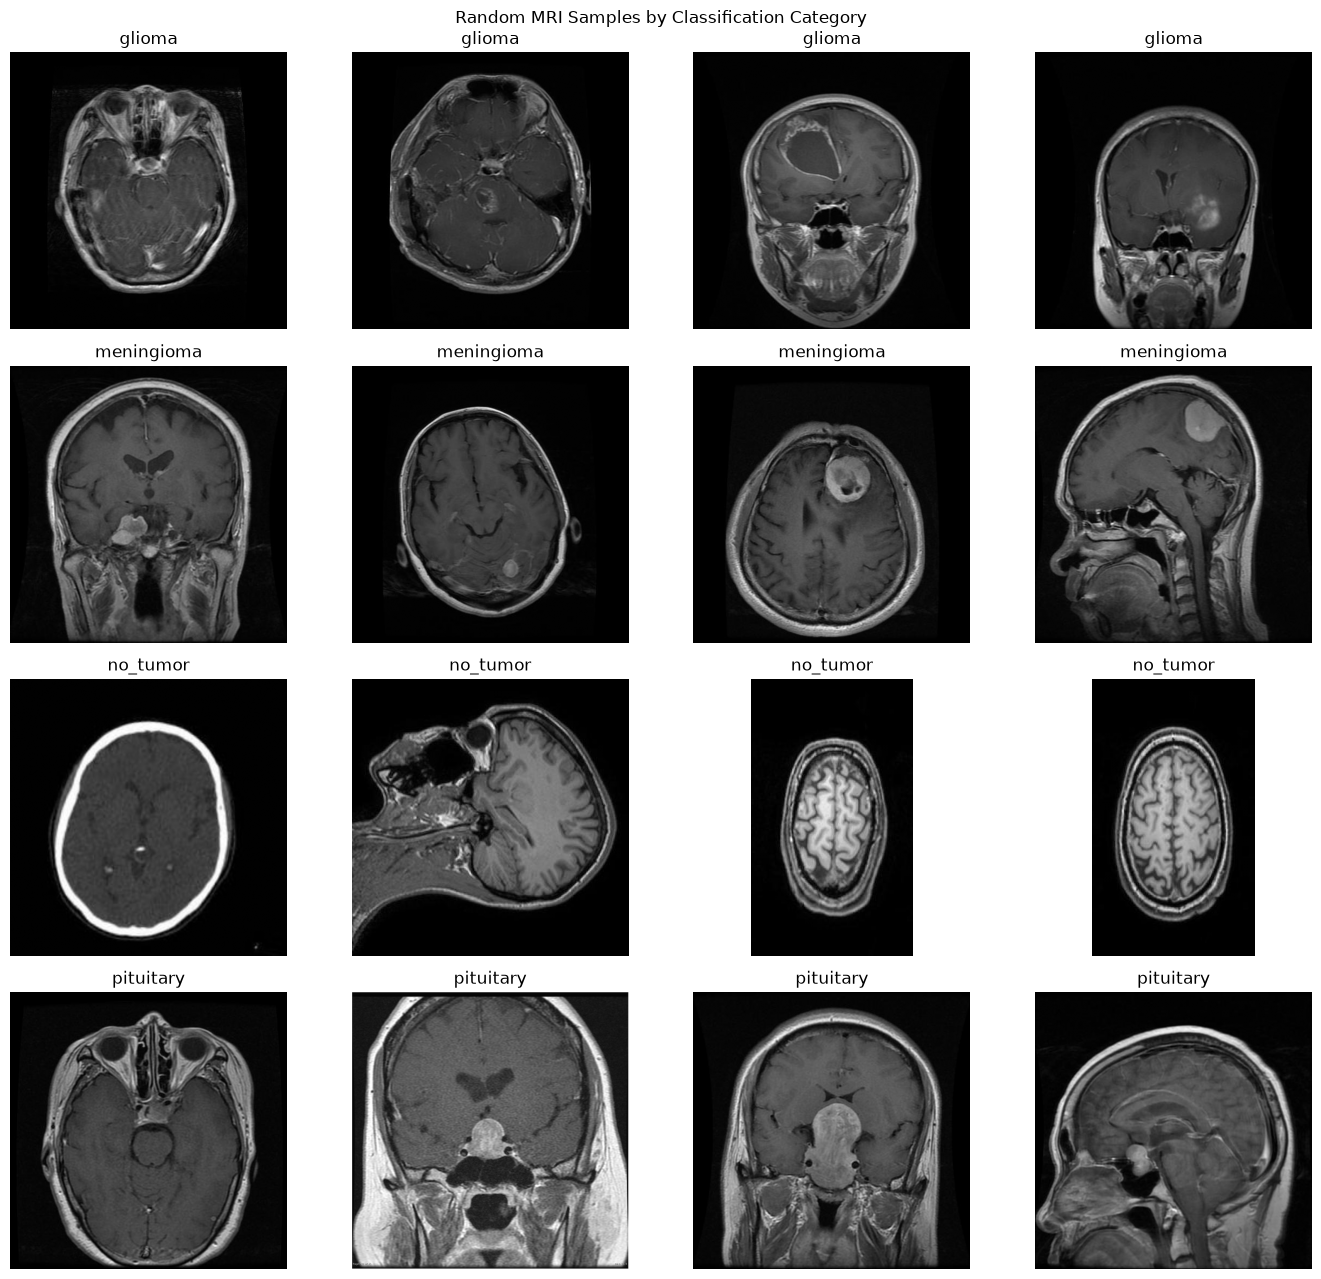

In [10]:
import random

random.seed(42)

fig, axes = plt.subplots(4, 4, figsize=(14, 13))

for row, class_name in enumerate(CLASSES):

    image_paths = get_image_files(TRAIN_DIR / class_name)

    selected_images = random.sample(
        image_paths,
        min(4, len(image_paths))
    )

    for col, image_path in enumerate(selected_images):

        with Image.open(image_path) as image:
            image = image.convert("L")
            axes[row, col].imshow(image, cmap="gray")

        axes[row, col].set_title(class_name)
        axes[row, col].axis("off")

plt.suptitle("Random MRI Samples by Classification Category")
plt.tight_layout()
plt.show()

In [11]:
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

random.seed(42)

intensity_records = []

for class_name in CLASSES:

    image_paths = get_image_files(TRAIN_DIR / class_name)

    # Sample 50 images per class
    selected_images = random.sample(
        image_paths,
        min(50, len(image_paths))
    )

    for image_path in selected_images:

        with Image.open(image_path) as image:

            grayscale = np.asarray(image.convert("L"))

            intensity_records.append({
                "Class": class_name,
                "Mean_Intensity": grayscale.mean(),
                "Std_Intensity": grayscale.std(),
                "Min_Intensity": grayscale.min(),
                "Max_Intensity": grayscale.max()
            })

intensity_df = pd.DataFrame(intensity_records)

print(intensity_df.groupby("Class").mean(numeric_only=True).round(2))

            Mean_Intensity  Std_Intensity  Min_Intensity  Max_Intensity
Class                                                                  
glioma               31.92          37.02           0.00         254.24
meningioma           41.65          44.84           0.04         254.84
no_tumor             53.41          55.31           0.02         250.78
pituitary            50.78          41.68           0.00         254.32


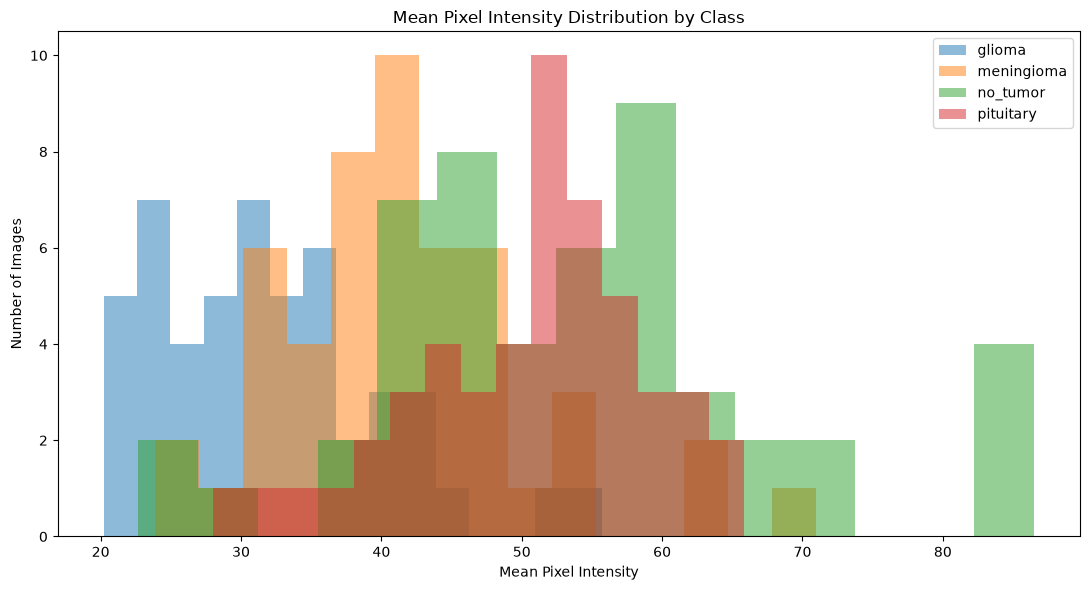

In [12]:
plt.figure(figsize=(11, 6))

for class_name in CLASSES:

    values = intensity_df[
        intensity_df["Class"] == class_name
    ]["Mean_Intensity"]

    plt.hist(
        values,
        bins=15,
        alpha=0.5,
        label=class_name
    )

plt.title("Mean Pixel Intensity Distribution by Class")
plt.xlabel("Mean Pixel Intensity")
plt.ylabel("Number of Images")
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
mode_summary = (
    image_df.groupby(["Class", "Mode"])
    .size()
    .unstack(fill_value=0)
)

print(mode_summary)

Mode           L   RGB
Class                 
glioma      1227   174
meningioma   709   926
no_tumor       0  1207
pituitary    930   827


In [14]:
mode_analysis = (
    image_df.groupby(["Class", "Mode"])
    .size()
    .unstack(fill_value=0)
)

mode_percentages = (
    mode_analysis.div(mode_analysis.sum(axis=1), axis=0) * 100
)

print("Image mode counts:")
print(mode_analysis)

print("\nImage mode percentages:")
print(mode_percentages.round(2))

Image mode counts:
Mode           L   RGB
Class                 
glioma      1227   174
meningioma   709   926
no_tumor       0  1207
pituitary    930   827

Image mode percentages:
Mode            L     RGB
Class                    
glioma      87.58   12.42
meningioma  43.36   56.64
no_tumor     0.00  100.00
pituitary   52.93   47.07


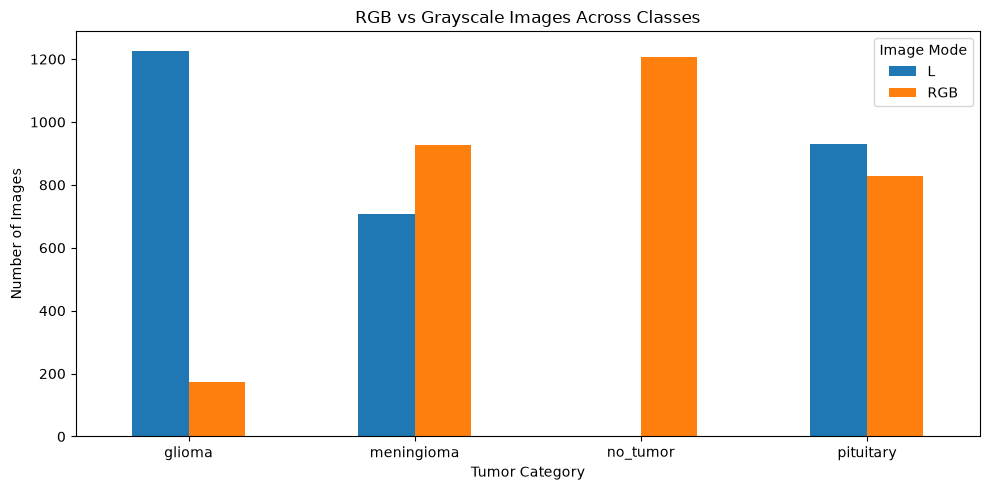

In [15]:
mode_analysis.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("RGB vs Grayscale Images Across Classes")
plt.xlabel("Tumor Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.legend(title="Image Mode")
plt.tight_layout()
plt.show()

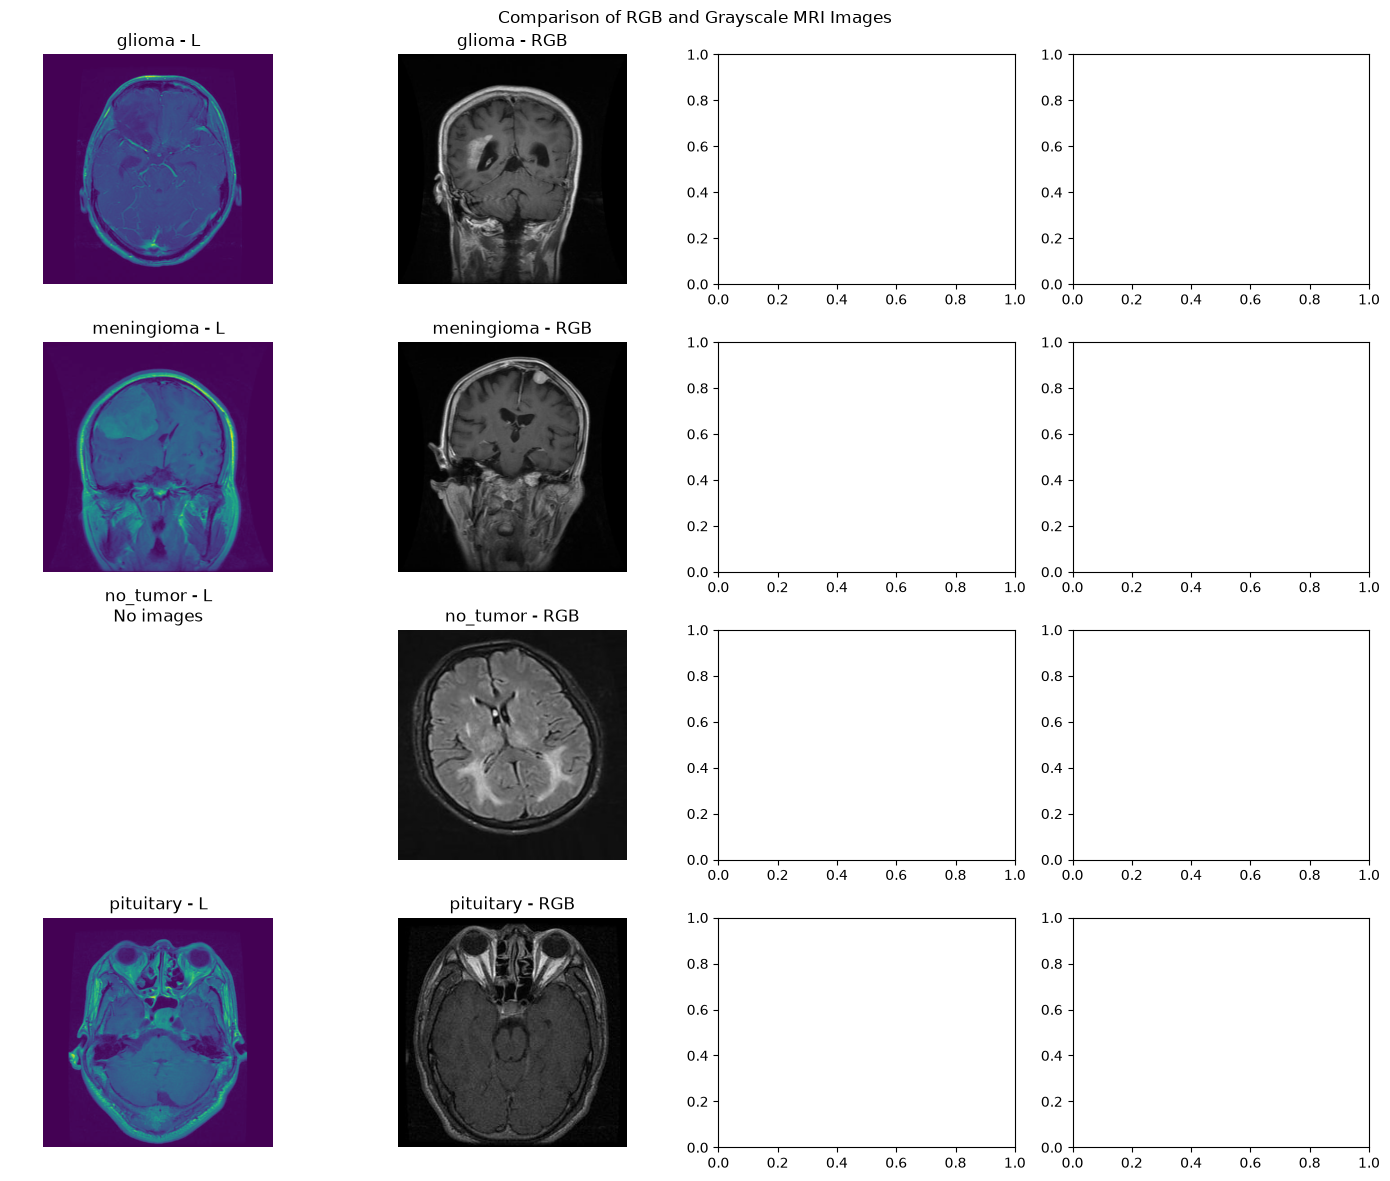

In [16]:
import random

random.seed(42)

fig, axes = plt.subplots(4, 4, figsize=(14, 12))

for row, class_name in enumerate(CLASSES):

    for col, mode in enumerate(["L", "RGB"]):

        candidates = image_df[
            (image_df["Class"] == class_name) &
            (image_df["Mode"] == mode)
        ]

        if candidates.empty:
            axes[row, col].set_title(
                f"{class_name} - {mode}\nNo images"
            )
            axes[row, col].axis("off")
            continue

        selected = candidates.sample(
            n=1,
            random_state=42
        ).iloc[0]

        image_path = (
            TRAIN_DIR if selected["Split"] == "Train"
            else TEST_DIR
        ) / class_name / selected["Filename"]

        with Image.open(image_path) as image:
            axes[row, col].imshow(image)

        axes[row, col].set_title(
            f"{class_name} - {mode}"
        )
        axes[row, col].axis("off")

plt.suptitle("Comparison of RGB and Grayscale MRI Images")
plt.tight_layout()
plt.show()

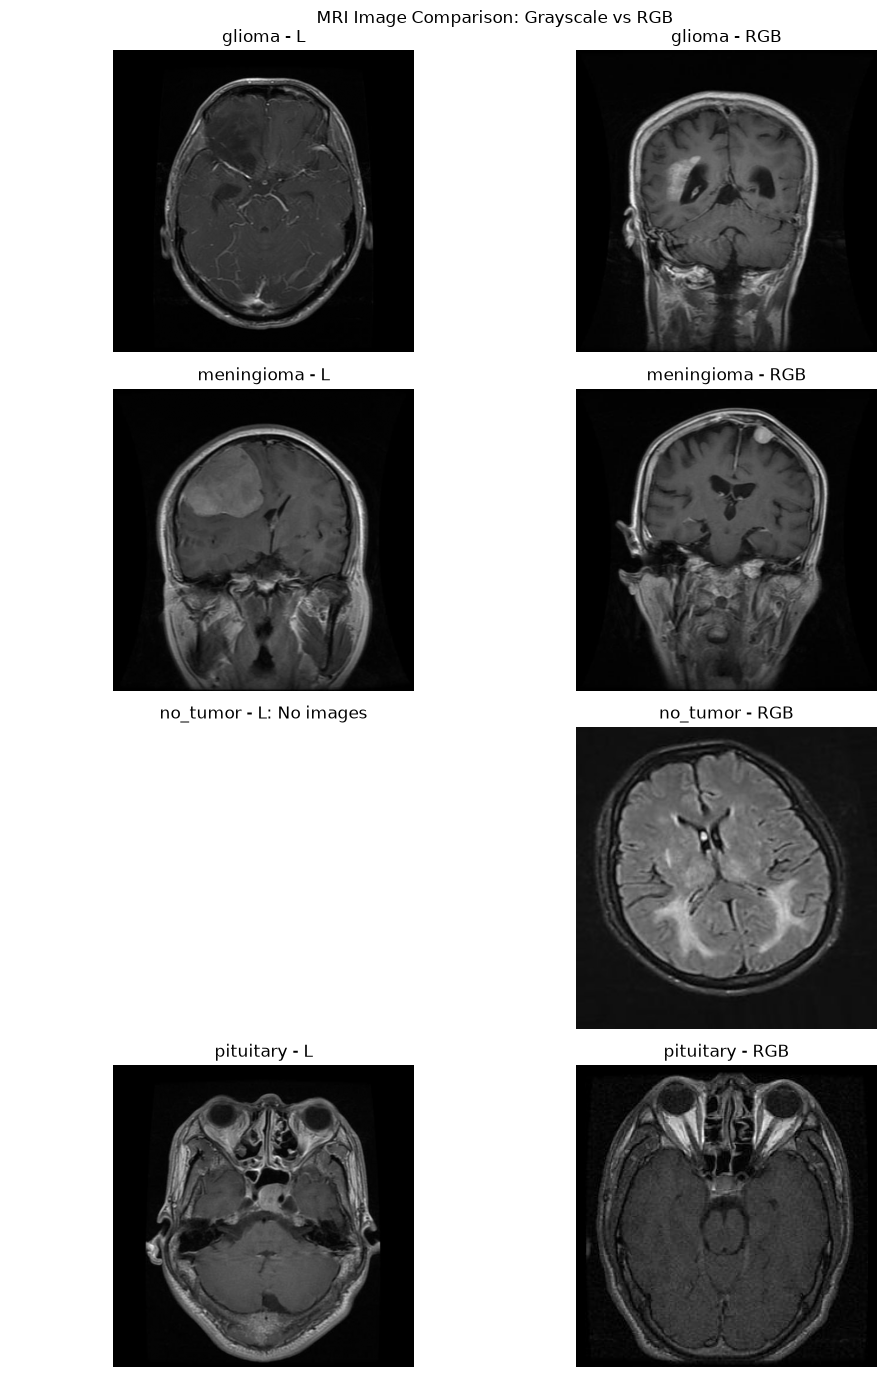

In [17]:
import random
import matplotlib.pyplot as plt
from PIL import Image

random.seed(42)

fig, axes = plt.subplots(4, 2, figsize=(10, 14))

for row, class_name in enumerate(CLASSES):

    for col, mode in enumerate(["L", "RGB"]):

        candidates = image_df[
            (image_df["Class"] == class_name) &
            (image_df["Mode"] == mode)
        ]

        ax = axes[row, col]

        if candidates.empty:
            ax.set_title(f"{class_name} - {mode}: No images")
            ax.axis("off")
            continue

        selected = candidates.sample(
            n=1,
            random_state=42
        ).iloc[0]

        image_path = (
            TRAIN_DIR if selected["Split"] == "Train"
            else TEST_DIR
        ) / class_name / selected["Filename"]

        with Image.open(image_path) as image:
            if mode == "L":
                ax.imshow(image, cmap="gray")
            else:
                ax.imshow(image)

        ax.set_title(f"{class_name} - {mode}")
        ax.axis("off")

plt.suptitle("MRI Image Comparison: Grayscale vs RGB")
plt.tight_layout()
plt.show()

In [18]:
rgb_records = []

for _, row in image_df[image_df["Mode"] == "RGB"].iterrows():

    split_dir = TRAIN_DIR if row["Split"] == "Train" else TEST_DIR

    image_path = split_dir / row["Class"] / row["Filename"]

    with Image.open(image_path) as image:

        rgb = np.asarray(image.convert("RGB")).astype(np.int16)

        r = rgb[:, :, 0]
        g = rgb[:, :, 1]
        b = rgb[:, :, 2]

        rg_diff = np.abs(r - g).mean()
        gb_diff = np.abs(g - b).mean()
        rb_diff = np.abs(r - b).mean()

        rgb_records.append({
            "Class": row["Class"],
            "Filename": row["Filename"],
            "RG_Difference": rg_diff,
            "GB_Difference": gb_diff,
            "RB_Difference": rb_diff,
            "Mean_Channel_Difference": (
                rg_diff + gb_diff + rb_diff
            ) / 3
        })

rgb_df = pd.DataFrame(rgb_records)

print("RGB images analyzed:", len(rgb_df))

print("\nChannel differences by class:")

print(
    rgb_df.groupby("Class")[
        [
            "RG_Difference",
            "GB_Difference",
            "RB_Difference",
            "Mean_Channel_Difference"
        ]
    ].mean().round(4)
)

RGB images analyzed: 3134

Channel differences by class:
            RG_Difference  GB_Difference  RB_Difference  \
Class                                                     
glioma                0.0            0.0            0.0   
meningioma            0.0            0.0            0.0   
no_tumor              0.0            0.0            0.0   
pituitary             0.0            0.0            0.0   

            Mean_Channel_Difference  
Class                                
glioma                          0.0  
meningioma                      0.0  
no_tumor                        0.0  
pituitary                       0.0  


In [19]:
tolerance = 0.0

rgb_df["Is_Grayscale_Like"] = (
    rgb_df["Mean_Channel_Difference"] <= tolerance
)

print(
    rgb_df.groupby("Class")["Is_Grayscale_Like"]
    .agg(["sum", "count", "mean"])
)

             sum  count  mean
Class                        
glioma       174    174   1.0
meningioma   926    926   1.0
no_tumor    1207   1207   1.0
pituitary    827    827   1.0


In [20]:
import hashlib
from collections import defaultdict

def calculate_image_hash(image_path):

    with Image.open(image_path) as image:

        # Standardize representation
        grayscale = image.convert("L")

        # Include dimensions to distinguish differently sized images
        image_bytes = (
            str(grayscale.size).encode()
            + grayscale.tobytes()
        )

        return hashlib.sha256(image_bytes).hexdigest()


duplicate_groups = defaultdict(list)

for split_name, split_dir in [
    ("Train", TRAIN_DIR),
    ("Test", TEST_DIR)
]:

    for class_name in CLASSES:

        image_paths = get_image_files(
            split_dir / class_name
        )

        for image_path in image_paths:

            image_hash = calculate_image_hash(image_path)

            duplicate_groups[image_hash].append({
                "Split": split_name,
                "Class": class_name,
                "Filename": image_path.name,
                "Path": str(image_path)
            })


duplicates = {
    image_hash: records
    for image_hash, records in duplicate_groups.items()
    if len(records) > 1
}

print("Total unique image hashes:", len(duplicate_groups))
print("Duplicate image groups:", len(duplicates))

print(
    "Total images belonging to duplicate groups:",
    sum(len(records) for records in duplicates.values())
)

Total unique image hashes: 5856
Duplicate image groups: 134
Total images belonging to duplicate groups: 278


In [21]:
duplicate_records = []

for image_hash, records in duplicates.items():

    for record in records:

        duplicate_records.append({
            "Hash": image_hash,
            "Split": record["Split"],
            "Class": record["Class"],
            "Filename": record["Filename"]
        })


duplicates_df = pd.DataFrame(duplicate_records)

if not duplicates_df.empty:

    print("\nDuplicate distribution:")

    print(
        duplicates_df.groupby(["Split", "Class"])
        .size()
    )

else:

    print("No exact duplicate images detected.")


Duplicate distribution:
Split  Class     
Test   glioma          2
       meningioma    102
       no_tumor        2
       pituitary       5
Train  meningioma    123
       no_tumor       18
       pituitary      26
dtype: int64


In [22]:
cross_split_duplicates = []

for image_hash, records in duplicates.items():

    splits = {record["Split"] for record in records}

    if len(splits) > 1:

        cross_split_duplicates.append(records)


print(
    "Duplicate groups appearing in both train and test:",
    len(cross_split_duplicates)
)

for index, records in enumerate(cross_split_duplicates[:10], start=1):

    print(f"\nDuplicate group {index}:")

    for record in records:

        print(
            record["Split"],
            "|",
            record["Class"],
            "|",
            record["Filename"]
        )

Duplicate groups appearing in both train and test: 98

Duplicate group 1:
Train | meningioma | brisc2025_train_01210_me_ax_t1.jpg
Test | meningioma | brisc2025_test_00344_me_ax_t1.jpg

Duplicate group 2:
Train | meningioma | brisc2025_train_01246_me_ax_t1.jpg
Train | meningioma | brisc2025_train_01302_me_ax_t1.jpg
Test | meningioma | brisc2025_test_00313_me_ax_t1.jpg

Duplicate group 3:
Train | meningioma | brisc2025_train_01247_me_ax_t1.jpg
Train | meningioma | brisc2025_train_01268_me_ax_t1.jpg
Train | meningioma | brisc2025_train_01386_me_ax_t1.jpg
Test | meningioma | brisc2025_test_00262_me_ax_t1.jpg
Test | meningioma | brisc2025_test_00275_me_ax_t1.jpg

Duplicate group 4:
Train | meningioma | brisc2025_train_01249_me_ax_t1.jpg
Test | meningioma | brisc2025_test_00264_me_ax_t1.jpg

Duplicate group 5:
Train | meningioma | brisc2025_train_01250_me_ax_t1.jpg
Test | meningioma | brisc2025_test_00265_me_ax_t1.jpg

Duplicate group 6:
Train | meningioma | brisc2025_train_01252_me_ax_t1.jp

In [23]:
duplicate_group_summary = []

for image_hash, records in duplicate_groups.items():

    splits = {record["Split"] for record in records}
    classes = {record["Class"] for record in records}

    if splits == {"Train", "Test"}:
        duplicate_type = "Cross-split"

    elif splits == {"Train"}:
        duplicate_type = "Train-only"

    else:
        duplicate_type = "Test-only"

    duplicate_group_summary.append({
        "Hash": image_hash,
        "Duplicate_Type": duplicate_type,
        "Number_of_Files": len(records),
        "Number_of_Classes": len(classes),
        "Classes": ", ".join(sorted(classes))
    })

duplicate_groups_df = pd.DataFrame(duplicate_group_summary)

print("Duplicate group breakdown:")
print(
    duplicate_groups_df["Duplicate_Type"]
    .value_counts()
)

print("\nGroups containing different class labels:")
print(
    duplicate_groups_df[
        duplicate_groups_df["Number_of_Classes"] > 1
    ]
)

Duplicate group breakdown:
Duplicate_Type
Train-only     4864
Test-only       894
Cross-split      98
Name: count, dtype: int64

Groups containing different class labels:
Empty DataFrame
Columns: [Hash, Duplicate_Type, Number_of_Files, Number_of_Classes, Classes]
Index: []


In [24]:
cross_split_records = []

for image_hash, records in duplicate_groups.items():

    splits = {record["Split"] for record in records}

    if splits == {"Train", "Test"}:

        for record in records:

            cross_split_records.append({
                "Hash": image_hash,
                "Split": record["Split"],
                "Class": record["Class"],
                "Filename": record["Filename"]
            })

cross_split_df = pd.DataFrame(cross_split_records)

print("Cross-split duplicate files:")
print(len(cross_split_df))

print("\nCross-split duplicate distribution:")
print(
    cross_split_df.groupby(["Split", "Class"]).size()
)

print("\nNumber of cross-split duplicate groups:")
print(cross_split_df["Hash"].nunique())

Cross-split duplicate files:
205

Cross-split duplicate distribution:
Split  Class     
Test   meningioma    96
       pituitary      5
Train  meningioma    97
       pituitary      7
dtype: int64

Number of cross-split duplicate groups:
98


In [25]:
cross_class_groups = []

for image_hash, records in duplicate_groups.items():

    classes = {record["Class"] for record in records}

    if len(classes) > 1:

        cross_class_groups.append({
            "Hash": image_hash,
            "Classes": sorted(classes),
            "Files": [
                record["Filename"] for record in records
            ]
        })

print("Duplicate groups with conflicting class labels:",
      len(cross_class_groups))

for group in cross_class_groups[:10]:
    print(group)

Duplicate groups with conflicting class labels: 0


In [26]:
# Collect unique test filenames involved in cross-split duplicates

affected_test_images = {
    record["Filename"]
    for records in cross_split_duplicates
    for record in records
    if record["Split"] == "Test"
}

affected_train_images = {
    record["Filename"]
    for records in cross_split_duplicates
    for record in records
    if record["Split"] == "Train"
}

print("Affected training images:", len(affected_train_images))
print("Affected testing images:", len(affected_test_images))

print(
    "Percentage of test set affected:",
    round(len(affected_test_images) / 1000 * 100, 2),
    "%"
)

Affected training images: 104
Affected testing images: 101
Percentage of test set affected: 10.1 %


In [27]:
cross_split_group_sizes = pd.DataFrame([
    {
        "Train_Files": sum(
            record["Split"] == "Train" for record in records
        ),
        "Test_Files": sum(
            record["Split"] == "Test" for record in records
        ),
        "Total_Files": len(records)
    }
    for records in cross_split_duplicates
])

print(cross_split_group_sizes.describe())

print("\nLargest duplicate groups:")
print(
    cross_split_group_sizes
    .sort_values("Total_Files", ascending=False)
    .head(10)
    .to_string(index=False)
)

       Train_Files  Test_Files  Total_Files
count    98.000000   98.000000    98.000000
mean      1.061224    1.030612     2.091837
std       0.315128    0.173150     0.432846
min       1.000000    1.000000     2.000000
25%       1.000000    1.000000     2.000000
50%       1.000000    1.000000     2.000000
75%       1.000000    1.000000     2.000000
max       3.000000    2.000000     5.000000

Largest duplicate groups:
 Train_Files  Test_Files  Total_Files
           3           2            5
           3           1            4
           2           2            4
           1           2            3
           2           1            3
           1           1            2
           1           1            2
           1           1            2
           1           1            2
           1           1            2


In [28]:
within_split_duplicate_groups = {
    image_hash: records
    for image_hash, records in duplicate_groups.items()
    if len(records) > 1
    and len({record["Split"] for record in records}) == 1
}

print(
    "Within-split duplicate groups:",
    len(within_split_duplicate_groups)
)

print(
    "Cross-split duplicate groups:",
    len(cross_split_duplicates)
)

print(
    "Total actual duplicate groups:",
    len(within_split_duplicate_groups)
    + len(cross_split_duplicates)
)

Within-split duplicate groups: 36
Cross-split duplicate groups: 98
Total actual duplicate groups: 134


## 7. Near-Duplicate Image Detection

This experiment uses perceptual hashing to identify visually
similar MRI images across training and testing datasets.

Exact duplicate images are also identified separately so
that near-duplicate candidates can be investigated.

In [32]:
import imagehash

# Store image metadata and perceptual hashes
phash_records = []

for split_name, split_dir in [
    ("Train", TRAIN_DIR),
    ("Test", TEST_DIR)
]:

    for class_name in CLASSES:

        for image_path in get_image_files(split_dir / class_name):

            with Image.open(image_path) as image:

                # Standardize image representation
                grayscale = image.convert("L")

                # Calculate perceptual hash
                phash = imagehash.phash(grayscale)

                phash_records.append({
                    "Split": split_name,
                    "Class": class_name,
                    "Filename": image_path.name,
                    "Path": str(image_path),
                    "pHash": phash
                })

phash_df = pd.DataFrame(phash_records)

print("Images processed:", len(phash_df))
print("Perceptual hashes generated successfully.")

Images processed: 6000
Perceptual hashes generated successfully.


In [35]:
# Step 3: Optimized cross-split perceptual hash comparison

import numpy as np

# Convert perceptual hashes into arrays of bytes
train_hashes = phash_df[
    phash_df["Split"] == "Train"
].reset_index(drop=True)

test_hashes = phash_df[
    phash_df["Split"] == "Test"
].reset_index(drop=True)


def hashes_to_array(hash_series):
    return np.array([
        list(bytes.fromhex(str(h)))
        for h in hash_series
    ], dtype=np.uint8)


train_hash_array = hashes_to_array(train_hashes["pHash"])
test_hash_array = hashes_to_array(test_hashes["pHash"])


# Lookup table for counting set bits
bit_count_lookup = np.array(
    [bin(i).count("1") for i in range(256)],
    dtype=np.uint8
)


near_duplicate_candidates = []

batch_size = 64

for start in range(0, len(test_hash_array), batch_size):

    end = min(start + batch_size, len(test_hash_array))

    # XOR compares all hashes in this batch with training hashes
    xor_result = (
        test_hash_array[start:end, None, :]
        ^ train_hash_array[None, :, :]
    )

    # Calculate Hamming distances using vectorized operations
    distances = bit_count_lookup[xor_result].sum(axis=2)

    # Exclude exact matches (distance 0)
    # They have already been investigated using SHA-256
    rows, cols = np.where(
        (distances >= 1) & (distances <= 4)
    )

    for row, col in zip(rows, cols):

        test_index = start + row

        near_duplicate_candidates.append({
            "Test_Class": test_hashes.iloc[test_index]["Class"],
            "Train_Class": train_hashes.iloc[col]["Class"],
            "Test_Filename": test_hashes.iloc[test_index]["Filename"],
            "Train_Filename": train_hashes.iloc[col]["Filename"],
            "Hamming_Distance": int(distances[row, col])
        })

    print(f"Processed {end}/{len(test_hash_array)} test images")


near_duplicates_df = pd.DataFrame(near_duplicate_candidates)

print("\nNear-duplicate candidate pairs:", len(near_duplicates_df))

if not near_duplicates_df.empty:
    print(
        near_duplicates_df
        .sort_values("Hamming_Distance")
        .head(20)
        .to_string(index=False)
    )

Processed 64/1000 test images
Processed 128/1000 test images
Processed 192/1000 test images
Processed 256/1000 test images
Processed 320/1000 test images
Processed 384/1000 test images
Processed 448/1000 test images
Processed 512/1000 test images
Processed 576/1000 test images
Processed 640/1000 test images
Processed 704/1000 test images
Processed 768/1000 test images
Processed 832/1000 test images
Processed 896/1000 test images
Processed 960/1000 test images
Processed 1000/1000 test images

Near-duplicate candidate pairs: 312
Test_Class Train_Class                     Test_Filename                     Train_Filename  Hamming_Distance
    glioma      glioma brisc2025_test_00009_gl_ax_t1.jpg brisc2025_train_00022_gl_ax_t1.jpg                 2
    glioma      glioma brisc2025_test_00027_gl_ax_t1.jpg brisc2025_train_00035_gl_ax_t1.jpg                 2
 pituitary   pituitary brisc2025_test_00993_pi_sa_t1.jpg brisc2025_train_04977_pi_sa_t1.jpg                 2
    glioma      glioma bris

In [36]:
if not near_duplicates_df.empty:

    print("\nHamming distance distribution:")

    print(
        near_duplicates_df["Hamming_Distance"]
        .value_counts()
        .sort_index()
    )

    print("\nClass pair distribution:")

    print(
        near_duplicates_df.groupby(
            ["Train_Class", "Test_Class"]
        ).size()
    )


Hamming distance distribution:
Hamming_Distance
2     85
4    227
Name: count, dtype: int64

Class pair distribution:
Train_Class  Test_Class
glioma       glioma         70
meningioma   glioma          2
             meningioma     76
             no_tumor        1
no_tumor     no_tumor        1
pituitary    pituitary     162
dtype: int64


## 8. Visual Verification of Near-Duplicate Candidates

This experiment visually compares MRI image pairs identified
through perceptual hashing.

The purpose is to distinguish genuine near-duplicates
from unrelated images with similar anatomical structures.

In [37]:
# Select candidates with the smallest Hamming distance

strong_candidates = (
    near_duplicates_df[
        near_duplicates_df["Hamming_Distance"] == 2
    ]
    .drop_duplicates(
        subset=["Test_Filename", "Train_Filename"]
    )
    .reset_index(drop=True)
)

print("Strong candidate pairs:", len(strong_candidates))

print(strong_candidates.head(10).to_string(index=False))

Strong candidate pairs: 85
Test_Class Train_Class                     Test_Filename                     Train_Filename  Hamming_Distance
    glioma      glioma brisc2025_test_00009_gl_ax_t1.jpg brisc2025_train_00022_gl_ax_t1.jpg                 2
    glioma      glioma brisc2025_test_00027_gl_ax_t1.jpg brisc2025_train_00035_gl_ax_t1.jpg                 2
    glioma      glioma brisc2025_test_00061_gl_ax_t1.jpg brisc2025_train_00226_gl_ax_t1.jpg                 2
    glioma      glioma brisc2025_test_00068_gl_ax_t1.jpg brisc2025_train_00269_gl_ax_t1.jpg                 2
    glioma      glioma brisc2025_test_00069_gl_ax_t1.jpg brisc2025_train_00319_gl_ax_t1.jpg                 2
    glioma      glioma brisc2025_test_00069_gl_ax_t1.jpg brisc2025_train_00320_gl_ax_t1.jpg                 2
    glioma      glioma brisc2025_test_00074_gl_ax_t1.jpg brisc2025_train_00353_gl_ax_t1.jpg                 2
    glioma      glioma brisc2025_test_00075_gl_ax_t1.jpg brisc2025_train_00353_gl_ax_t1.jpg  

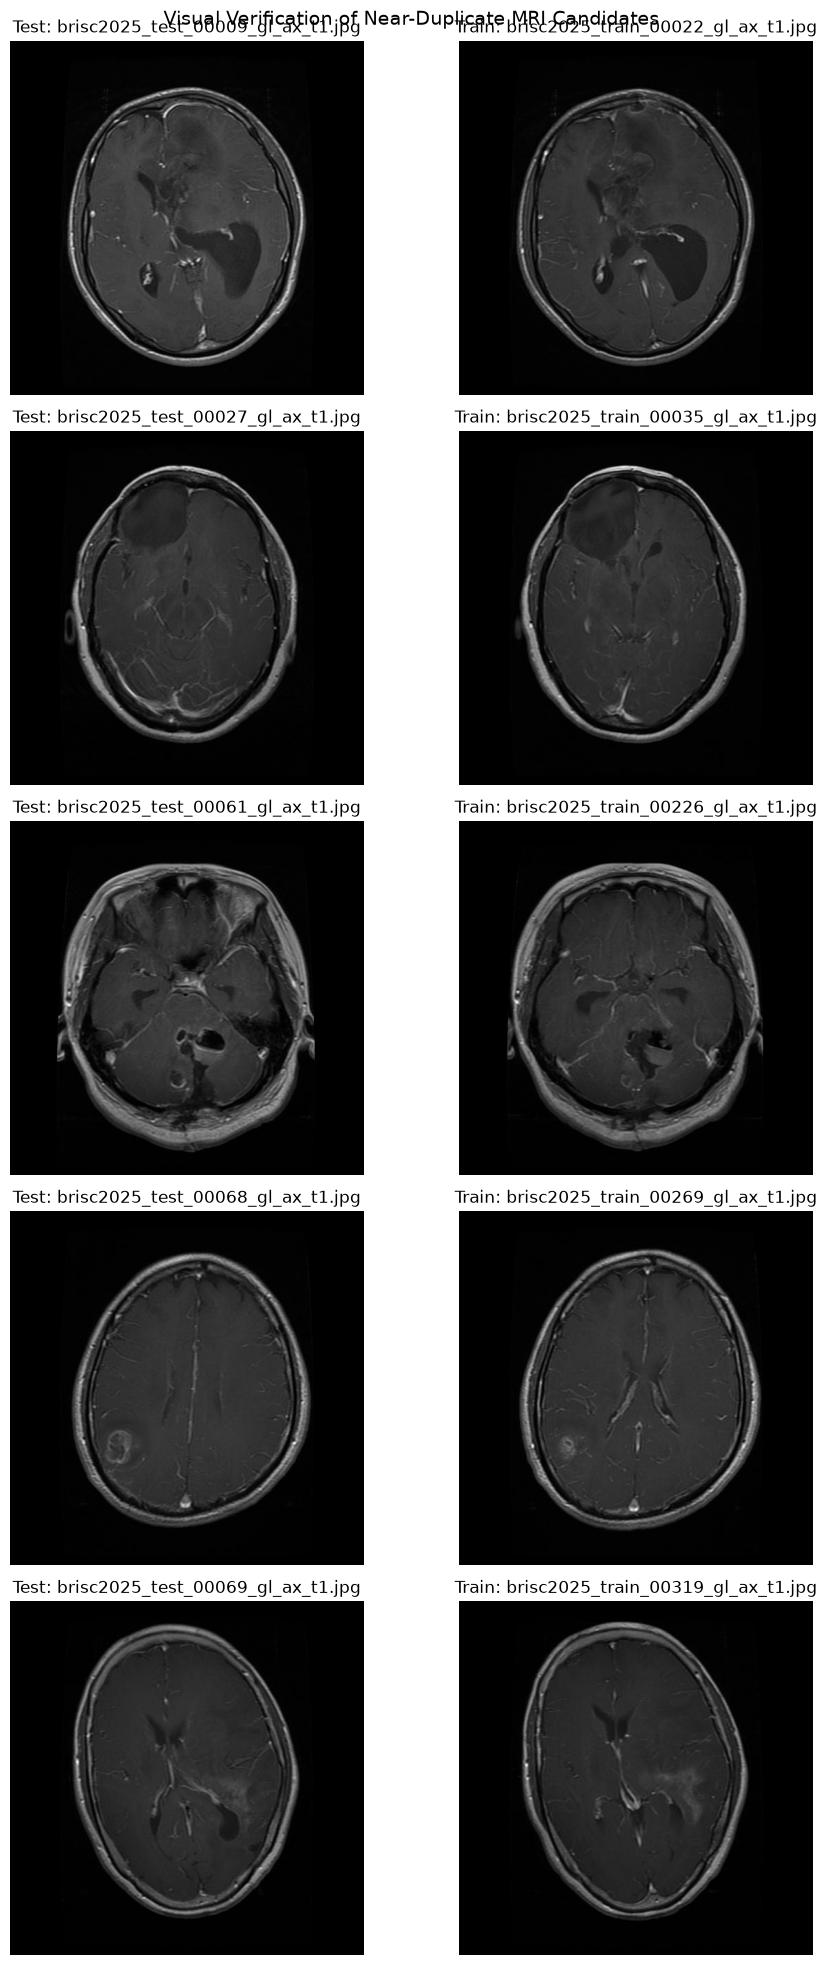

In [38]:
import matplotlib.pyplot as plt
from PIL import Image

# Inspect the first five strongest candidate pairs
sample_pairs = strong_candidates.head(5)

fig, axes = plt.subplots(5, 2, figsize=(10, 20))

for row_index, (_, pair) in enumerate(sample_pairs.iterrows()):

    test_path = (
        phash_df.loc[
            phash_df["Filename"] == pair["Test_Filename"],
            "Path"
        ].iloc[0]
    )

    train_path = (
        phash_df.loc[
            phash_df["Filename"] == pair["Train_Filename"],
            "Path"
        ].iloc[0]
    )

    with Image.open(test_path) as image:
        axes[row_index, 0].imshow(
            image.convert("L"),
            cmap="gray"
        )

    with Image.open(train_path) as image:
        axes[row_index, 1].imshow(
            image.convert("L"),
            cmap="gray"
        )

    axes[row_index, 0].set_title(
        f"Test: {pair['Test_Filename']}"
    )

    axes[row_index, 1].set_title(
        f"Train: {pair['Train_Filename']}"
    )

    axes[row_index, 0].axis("off")
    axes[row_index, 1].axis("off")

plt.suptitle(
    "Visual Verification of Near-Duplicate MRI Candidates",
    fontsize=14
)

plt.tight_layout()
plt.show()